# Solar Power Generation Data Analysis
## Notebook 01 — Plant 1: Dataset Understanding & the First Clue

This is the first chapter of a small **data detective story**. We receive data from two solar plants and a simple question from the business:

> *"Are our plants performing as they should?"*

Before answering, we need to understand the data and decide whether we can trust it.

### Learning objectives
- Understand the structure of inverter-level generation data and plant-level weather data
- Assess data **completeness**: are all the records there?
- Run a **physical sanity check**: do the values make sense for a solar plant?
- Turn data evidence into **questions for the business**

## About the dataset
Data from **two solar power plants in India**, collected over **34 days** (15 May – 17 June 2020). Each plant has two files:

| File | Level | Content |
|---|---|---|
| Generation data | Inverter (`SOURCE_KEY`) | DC power, AC power, daily and total yield |
| Weather sensor data | Plant (one sensor array) | Irradiation, ambient temperature, module temperature |

Each inverter has several strings of solar panels attached. Panels produce **DC** power, the inverter converts it to **AC** power for the grid.

Source: [Kaggle — Solar Power Generation Data](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data/data)

## 💡 Power (kW) vs. Energy (kWh)

Two closely related concepts with different physical and economic meaning.

| | Power | Energy |
|---|---|---|
| Unit | kW (kilowatt) | kWh (kilowatt-hour) |
| Physical meaning | The *rate* at which energy is produced at a given moment | The *total amount* produced over a period |
| Business meaning | Capacity, grid management, real-time optimisation | What is **sold and billed**: drives revenue |

$$\text{Energy (kWh)} = \text{Power (kW)} \times \text{Time (h)}$$

> **Example:** an inverter producing on average 100 kW over a 15-minute interval (0.25 h) generates 100 × 0.25 = **25 kWh**.

In our data, `DC_POWER` and `AC_POWER` are **power** (average over 15 minutes); `DAILY_YIELD` and `TOTAL_YIELD` are cumulative **energy** counters.

## Our approach: Exploratory Data Analysis (EDA)
1. **Import & inspection**: load, check types, dimensions, summary statistics
2. **Completeness**: are all expected records there?
3. **Plausibility**: do the values respect basic physics?

In [2]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("Libraries imported successfully")

Libraries imported successfully


## 1. Data import and initial inspection

In [3]:
def load_data(data_folder="../data",
              generation_file="Plant_1_Generation_Data.csv",
              weather_file="Plant_1_Weather_Sensor_Data.csv"):
    generation_df = pd.read_csv(os.path.join(data_folder, generation_file))
    weather_df = pd.read_csv(os.path.join(data_folder, weather_file))
    return generation_df, weather_df

generation_df, weather_df = load_data()

print(f"Generation data shape: {generation_df.shape}")
print(f"Weather data shape:    {weather_df.shape}")

Generation data shape: (68778, 7)
Weather data shape:    (3182, 6)


`.info()` is a quick health check: column names, data types, non-null counts.

In [4]:
generation_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB


`DATE_TIME` is stored as text (`object`). We convert it to a proper datetime so we can sort, filter and aggregate by time. We also extract the day and the time of day.

In [5]:
# Plant 1 generation file uses the day-month-year format
generation_df['DATE_TIME'] = pd.to_datetime(generation_df['DATE_TIME'], format='%d-%m-%Y %H:%M')
generation_df['DAY'] = generation_df['DATE_TIME'].dt.date
generation_df['DAYTIME'] = generation_df['DATE_TIME'].dt.time

generation_df.head(3)

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,DAY,DAYTIME
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020-05-15,00:00:00
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,2020-05-15,00:00:00
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,2020-05-15,00:00:00


> **Reading the output:** each row is one 15-minute measurement from one inverter (`SOURCE_KEY`).

In [6]:
generation_df.describe(include='all')

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,DAY,DAYTIME
count,68778,68778.0,68778,68778.000000,68778.000000,68778.000000,6.877800e+04,68778,68778
unique,NaN,NaN,22,NaN,NaN,NaN,NaN,34,96
top,NaN,NaN,bvBOhCH3iADSZry,NaN,NaN,NaN,NaN,2020-05-18,07:45:00
freq,NaN,NaN,3155,NaN,NaN,NaN,NaN,2112,748
mean,2020-06-01 08:02:49.458256896,4135001.0,NaN,3147.426211,307.802752,3295.968737,6.978712e+06,NaN,NaN
min,2020-05-15 00:00:00,4135001.0,NaN,0.000000,0.000000,0.000000,6.183645e+06,NaN,NaN
25%,2020-05-24 00:45:00,4135001.0,NaN,0.000000,0.000000,0.000000,6.512003e+06,NaN,NaN
50%,2020-06-01 14:30:00,4135001.0,NaN,429.000000,41.493750,2658.714286,7.146685e+06,NaN,NaN
75%,2020-06-09 20:00:00,4135001.0,NaN,6366.964286,623.618750,6274.000000,7.268706e+06,NaN,NaN
max,2020-06-17 23:45:00,4135001.0,NaN,14471.125000,1410.950000,9163.000000,7.846821e+06,NaN,NaN


> **22 inverters**, **34 days**, **96 samples per day** (one every 15 minutes: 24 h × 4).
>
> Keep an eye on the `mean` row of `DC_POWER` and `AC_POWER`. We will come back to it.

Now the weather dataset:

In [7]:
weather_df['DATE_TIME'] = pd.to_datetime(weather_df['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')
weather_df['DAY'] = weather_df['DATE_TIME'].dt.date
weather_df['DAYTIME'] = weather_df['DATE_TIME'].dt.time

weather_df.describe()

,DATE_TIME,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3182,3182.0,3182.000000,3182.000000,3182.000000
mean,2020-06-01 05:52:22.080452608,4135001.0,25.531606,31.091015,0.228313
min,2020-05-15 00:00:00,4135001.0,20.398505,18.140415,0.000000
25%,2020-05-23 22:48:45,4135001.0,22.705182,21.090553,0.000000
50%,2020-06-01 09:52:30,4135001.0,24.613814,24.618060,0.024653
75%,2020-06-09 16:56:15,4135001.0,27.920532,41.307840,0.449588
max,2020-06-17 23:45:00,4135001.0,35.252486,65.545714,1.221652
std,NaN,0.0,3.354856,12.261222,0.300836


> A **single sensor array** for the whole plant: ambient temperature, module temperature and irradiation (kW/m²) every 15 minutes.

## 2. Completeness: are all the records there?

With 22 inverters × 96 readings per day we expect **2,112 records per day**.

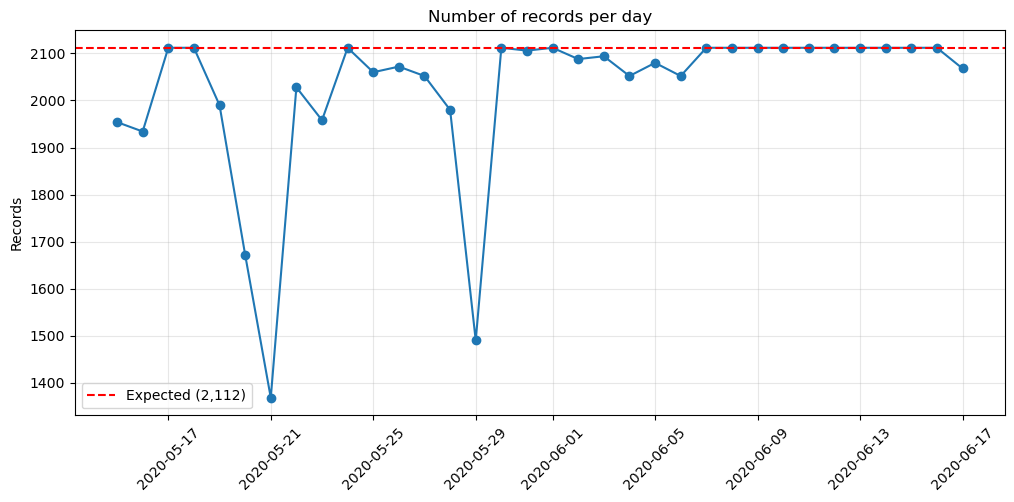

In [8]:
records_per_day = generation_df['DAY'].value_counts().sort_index()

plt.plot(records_per_day.index, records_per_day.values, marker='o')
plt.axhline(22 * 96, color='red', linestyle='--', label='Expected (2,112)')
plt.title('Number of records per day')
plt.ylabel('Records')
plt.legend()
plt.xticks(rotation=45)
plt.show()

> Some days have fewer records than expected. Which inverters, which days? We compute the **completeness** of each inverter on each day: records received / 96.

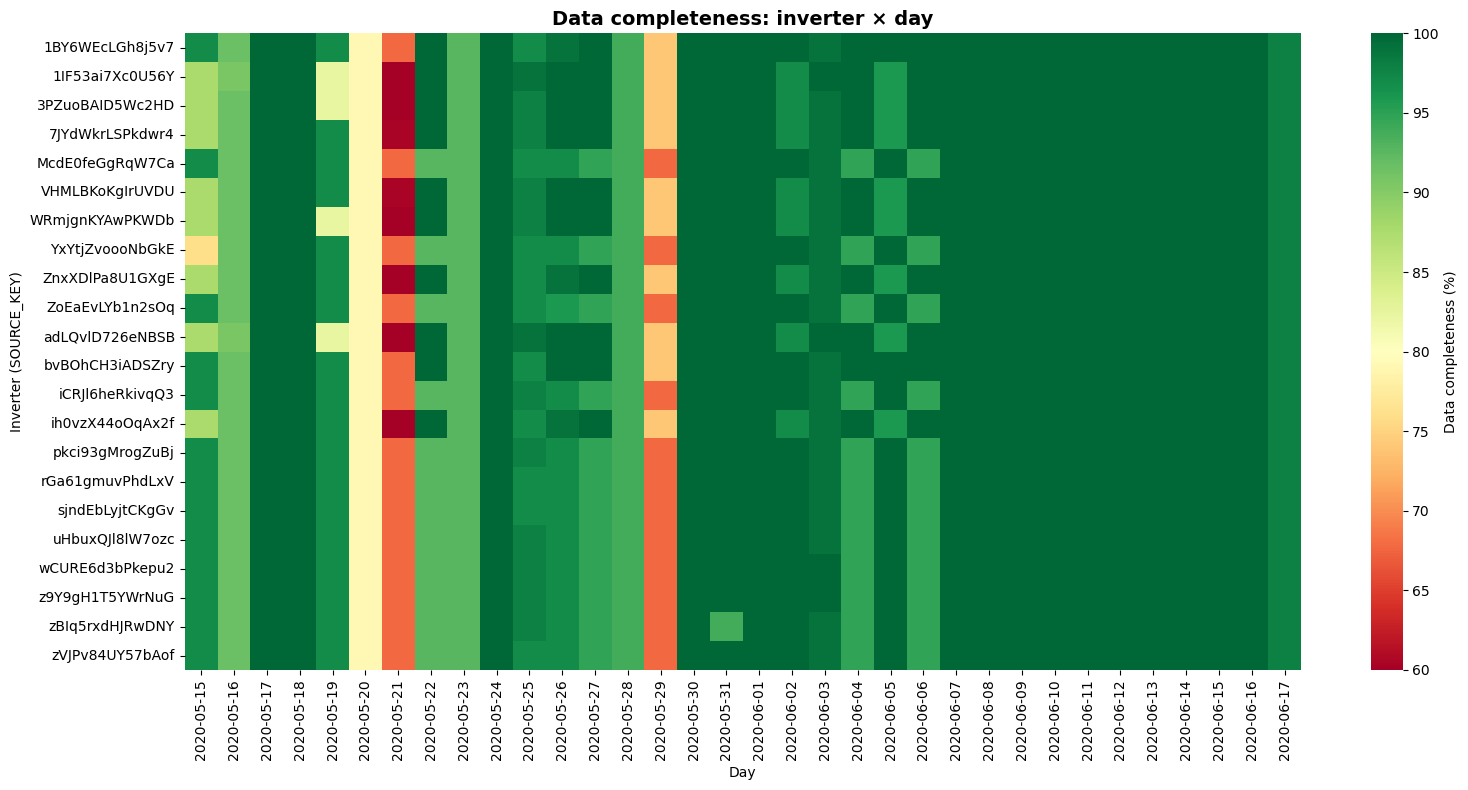

Average completeness:          95.8%
Inverter-days at 100%:         430 of 748
Inverter-days with no data:    0


In [9]:
SAMPLES_PER_DAY = 96

completeness = (
    generation_df.groupby(['SOURCE_KEY', 'DAY']).size()
    .div(SAMPLES_PER_DAY).mul(100)
    .unstack()            # rows: inverters, columns: days
)

plt.figure(figsize=(16, 8))
sns.heatmap(completeness, cmap='RdYlGn', vmin=60, vmax=100,
            cbar_kws={'label': 'Data completeness (%)'})
plt.grid(False)
plt.title('Data completeness: inverter × day', fontsize=14, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Inverter (SOURCE_KEY)')
plt.tight_layout()
plt.show()

print(f"Average completeness:          {completeness.mean().mean():.1f}%")
print(f"Inverter-days at 100%:         {(completeness == 100).sum().sum()} of {completeness.size}")
print(f"Inverter-days with no data:    {completeness.isna().sum().sum()}")

> **Takeaway:** completeness is ~96% and very uniform across inverters. The gaps are concentrated on a few days (20, 21 and 29 May) where **all inverters lose data at the same time**. A plant-wide gap points to the **logging / communication system** rather than to the panels.
>
> Questions for the plant operator:
> - What happened on the days with missing data? Planned shutdown, malfunction, or a logging problem?
> - Can missing data be recovered from backup systems?

## 3. Plausibility: the first clue 

Completeness tells us whether the records **exist**. It says nothing about whether the values are **right**.

A simple physical check: the inverter converts DC into AC with small losses. Modern inverters have a conversion efficiency of about **96–99%** (datasheet values, measured with standard protocols such as the CEC weighted efficiency; NREL's PVWatts model assumes 96% by default), so we expect:

$$\text{AC\_POWER} \approx 0.97 \times \text{DC\_POWER}$$

Let's go back to the summary statistics.

In [10]:
generation_df[['DC_POWER', 'AC_POWER']].describe().round(1)

,DC_POWER,AC_POWER
count,68778.0,68778.0
mean,3147.4,307.8
std,4036.5,394.4
min,0.0,0.0
25%,0.0,0.0
50%,429.0,41.5
75%,6367.0,623.6
max,14471.1,1411.0


> The average DC power is about **ten times** the AC power. That cannot be a 3% conversion loss. Let's look at every reading.

DC / AC ratio — median: 10.22
DC / AC ratio — 5th–95th percentile: 10.18 – 10.35


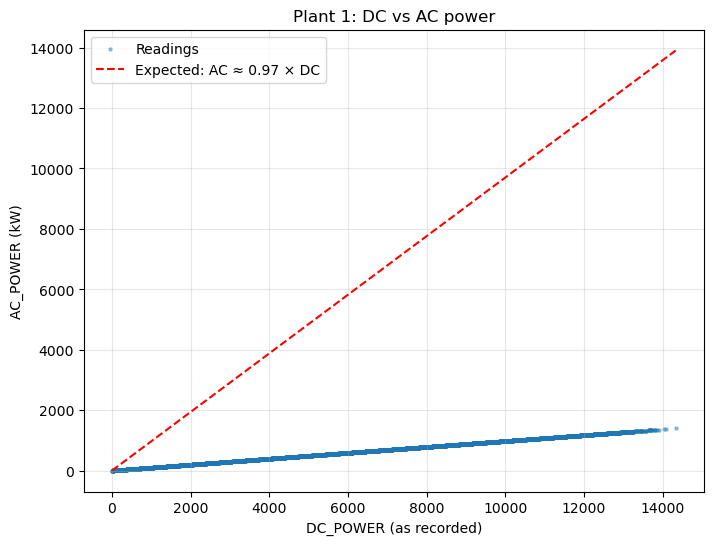

In [11]:
producing = generation_df[generation_df['AC_POWER'] > 0]
ratio = producing['DC_POWER'] / producing['AC_POWER']

print(f"DC / AC ratio — median: {ratio.median():.2f}")
print(f"DC / AC ratio — 5th–95th percentile: {ratio.quantile(0.05):.2f} – {ratio.quantile(0.95):.2f}")

sample = producing.sample(5000, random_state=42)
max_dc = sample['DC_POWER'].max()

plt.figure(figsize=(8, 6))
plt.scatter(sample['DC_POWER'], sample['AC_POWER'], s=5, alpha=0.4, label='Readings')
plt.plot([0, max_dc], [0, 0.97 * max_dc], 'r--', label='Expected: AC ≈ 0.97 × DC')
plt.xlabel('DC_POWER (as recorded)')
plt.ylabel('AC_POWER (kW)')
plt.title('Plant 1: DC vs AC power')
plt.legend()
plt.show()

> *How to read the percentiles:* the 5th percentile is the value below which 5% of readings fall, the 95th the value below which 95% fall. Together they bound the **central 90%** of the data, ignoring the extreme tails. Here 90% of readings have a ratio between 10.18 and 10.35: extremely narrow.
>
> **First clue:** every reading sits on a line with slope ~1/10. The ratio is extremely stable (median ≈ 10.2), so this is not random noise: it looks like **DC power recorded on a different scale** (for example ×10, or a different unit).
>
> What should a data scientist do?
>
> | Option | Risk |
> |---|---|
> | Divide DC by 10 and move on | We are *guessing* the cause. If wrong, every downstream number is wrong |
> | Use only AC power | Safe for production analysis, but we lose the DC/AC diagnostics |
> | **Ask the plant operator** how DC is measured and logged | Slower, but it is the only way to *know* |
>
> Before asking, can the data itself tell us **which** of the two is wrong?

### Which one is wrong, DC or AC? Energy decides
We have a third, independent measurement: `DAILY_YIELD`, the energy counter of each inverter (kWh). If power is correct, integrating it over the day must give the daily energy:

$$\text{Energy} = \sum_{\text{readings}} \text{Power} \times 0.25\ \text{h}$$

Let's test it with both AC and DC power, on inverter-days with all 96 readings.

In [14]:
daily = (generation_df.groupby(['SOURCE_KEY', 'DAY'])
         .agg(readings=('AC_POWER', 'size'),
              energy_from_ac=('AC_POWER', lambda p: (p * 0.25).sum()),
              energy_from_dc=('DC_POWER', lambda p: (p * 0.25).sum()),
              daily_yield=('DAILY_YIELD', 'max')))
daily = daily[daily['readings'] == SAMPLES_PER_DAY]
daily.head()

readings  energy_from_ac  energy_from_dc  \
SOURCE_KEY      DAY                                                    
1BY6WEcLGh8j5v7 2020-05-17        96     7043.212500    72009.955359   
                2020-05-18        96     4992.626786    51007.575892   
                2020-05-22        96     6864.158482    70202.267856   
                2020-05-24        96     7555.091964    77277.933036   
                2020-05-27        96     6148.901339    62812.629463   

                            daily_yield  
SOURCE_KEY      DAY                      
1BY6WEcLGh8j5v7 2020-05-17       7045.0  
                2020-05-18       4998.0  
                2020-05-22       6848.0  
                2020-05-24       7537.0  
                2020-05-27       6164.0

> **Case solved for Plant 1.** AC power integrated over the day matches the energy counter exactly (ratio 1.000), so **AC power and DAILY_YIELD are consistent and DC power is the one off by a factor ~10**.
>
> Two bonus lessons:
> - The check also confirms that each reading is the **average power over 15 minutes**: power × 0.25 h adds up to the energy counter.
> - When two measurements disagree, look for a **third, independent one** to arbitrate.
>
> We still need the operator to confirm *why* DC is off, but we now know *which* variable to trust.

## Summary

| Finding | Question for the business |
|---|---|
| ~96% completeness, with plant-wide gaps on a few days | Logging or communication failure? Can the data be recovered? |
| DC power ≈ 10 × AC power on every reading; AC is consistent with the energy counter | How is DC power measured and logged? Unit or scaling error? |

**Lessons:** complete data is not the same as *correct* data. Check values against basic physics, and when two measurements disagree, use a third one to decide.

In a real project we would now call the operator. For this course we park Plant 1 and move on.

➡️ **Next notebook:** Plant 2 passes the same checks. Or does it?